In [1]:
# Cell 1 — Setup and Class-E PA Harmonic Model

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

V_DD, P_out, f0 = 4.85, 1.65, 14.0e6
w0 = 2*np.pi*f0
R_opt = 0.5768 * V_DD**2 / P_out
R_ant = 50.0
w_notch = 2*np.pi*2*f0

# Class-E PA natural harmonic output (before the LPF).
# In a real Class-E PA, the series resonant tank acts as a bandpass,
# but finite Q and non-ideal switching leave harmonics on the output.
# Typical measured values for a QRP Class-E PA are roughly:
# 2nd harmonic: -20 dBc, 3rd harmonic: -30 dBc, 4th: -40 dBc.
def pa_harmonics(n):
    if n == 1: return 0.0
    return -10.0 - 10.0 * n   # e.g., -20 dBc at 2f0, -30 dBc at 3f0

print(f"R_opt = {R_opt:.3f} ohm, f0 = {f0/1e6:.1f} MHz")
print("PA Harmonic Profile (Assumed):")
for n in range(2, 6):
    print(f"  {n}f0 ({n*f0/1e6:.0f} MHz): {pa_harmonics(n):.0f} dBc")

R_opt = 8.223 ohm, f0 = 14.0 MHz
PA Harmonic Profile (Assumed):
  2f0 (28 MHz): -30 dBc
  3f0 (42 MHz): -40 dBc
  4f0 (56 MHz): -50 dBc
  5f0 (70 MHz): -60 dBc


In [2]:
# Cell 2 — ABCD Matrix Helpers

def abcd_shunt_c(C, w):
    return np.array([[1, 0], [1j*w*C, 1]], dtype=complex)

def abcd_series_parallel_lc(L, C, w):
    denom = 1 - w**2 * L * C
    Z = 1e9 + 0j if abs(denom) < 1e-14 else (1j*w*L) / denom
    return np.array([[1, Z], [0, 1]], dtype=complex)

def s_from_abcd(abcd, R_in, R_out):
    A, B = abcd[0,0], abcd[0,1]
    C, D = abcd[1,0], abcd[1,1]
    d = A + B/R_out + C*R_in + D*R_in/R_out
    S11 = (A + B/R_out - C*R_in - D*R_in/R_out)/d
    S21 = 2.0 * np.sqrt(R_in/R_out)/d
    return S11, S21

def filter_s_params(C1, L2, C2, C3, w):
    abcd = (abcd_shunt_c(C1, w)
            @ abcd_series_parallel_lc(L2, C2, w)
            @ abcd_shunt_c(C3, w))
    return s_from_abcd(abcd, R_opt, R_ant)

In [3]:
# Cell 3 — Optimize the 4-element filter (C1, L2, C3; C2 derived)

def cost(x):
    C1, L2, C3 = x
    C2 = 1.0 / (w_notch**2 * L2)  # Derive C2 so notch is exactly on 2f0

    # Manufacturability constraints
    if C2 < 30e-12: return 1e6
    if not (30e-12 < C1 < 2000e-12): return 1e6
    if not (50e-9 < L2 < 3000e-9): return 1e6
    if not (30e-12 < C3 < 2000e-12): return 1e6

    S11_f0, S21_f0 = filter_s_params(C1, L2, C2, C3, w0)
    S11_2f0, S21_2f0 = filter_s_params(C1, L2, C2, C3, w_notch)

    # Passband: S21 -> 1, S11 -> 0
    passband = (1 - abs(S21_f0))**2 * 100 + abs(S11_f0)**2 * 100
    # Notch: S21(2f0) as small as possible
    notch = abs(S21_2f0)**2 * 1000

    return passband + notch

bounds = [
    (30e-12, 1500e-12),   # C1
    (100e-9, 2000e-9),    # L2
    (30e-12, 1500e-12),   # C3
]

result = differential_evolution(
    cost, bounds,
    strategy='best1bin', popsize=30, maxiter=3000,
    tol=1e-14, seed=42, polish=True, disp=False,
)

C1, L2, C3 = result.x
C2 = 1.0 / (w_notch**2 * L2)

print("\n=== Optimized 3-Element Filter Components ===")
print(f"  C1 = {C1*1e12:.1f} pF")
print(f"  L2 = {L2*1e9:.1f} nH")
print(f"  C2 = {C2*1e12:.1f} pF")
print(f"  C3 = {C3*1e12:.1f} pF")
print(f"  Notch freq = {1/(2*np.pi*np.sqrt(L2*C2))/1e6:.2f} MHz (target 28.00)")


=== Optimized 3-Element Filter Components ===
  C1 = 1222.8 pF
  L2 = 158.2 nH
  C2 = 204.3 pF
  C3 = 713.1 pF
  Notch freq = 28.00 MHz (target 28.00)



Harmonic   | Freq (MHz) | PA Native  | Filter     | Total Output | FCC Limit  | Margin  
-------------------------------------------------------------------------------------
1f0       |  14.0     |     0 dBc   |   0.0 dB   |     0.0 dBc   | -43 dBc    | -43.0 dB ❌
2f0       |  28.0     |   -30 dBc   | -86.2 dB   |  -116.2 dBc   | -43 dBc    |  73.2 dB ✅
3f0       |  42.0     |   -40 dBc   | -28.7 dB   |   -68.7 dBc   | -43 dBc    |  25.7 dB ✅
4f0       |  56.0     |   -50 dBc   | -29.0 dB   |   -79.0 dBc   | -43 dBc    |  36.0 dB ✅
5f0       |  70.0     |   -60 dBc   | -30.1 dB   |   -90.1 dBc   | -43 dBc    |  47.1 dB ✅

Worst-case margin to FCC: 25.7 dB


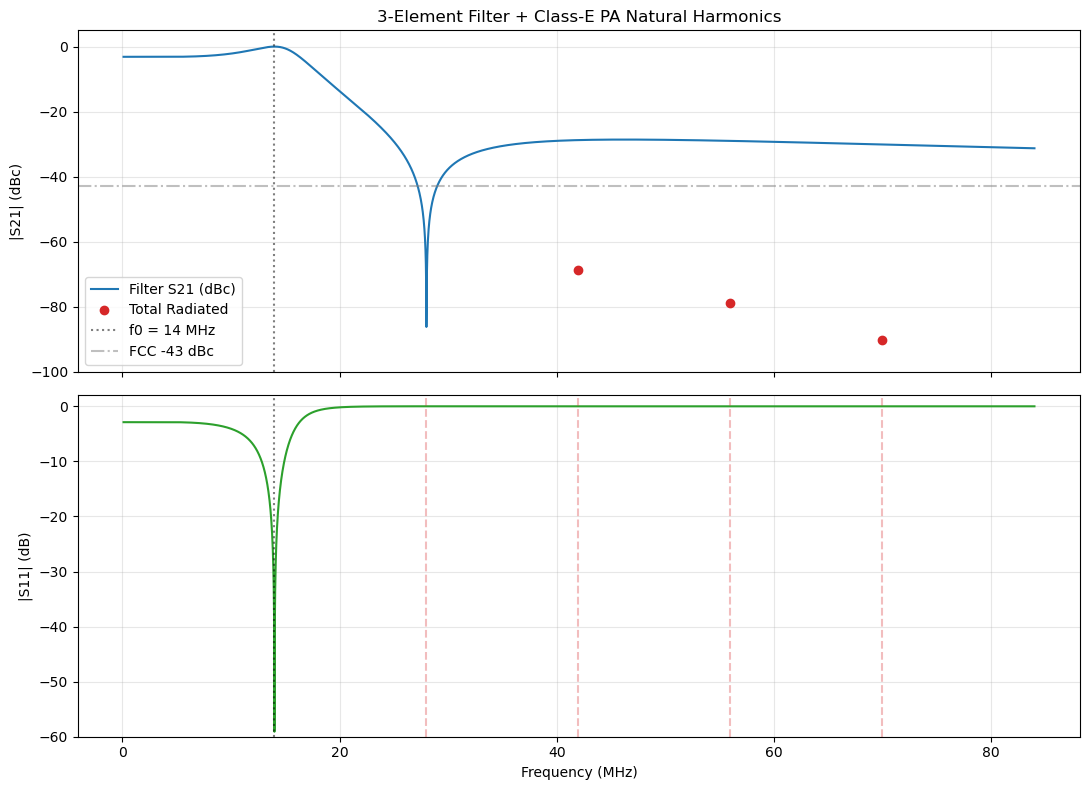

In [4]:
# Cell 4 — Compute Filter Response and Total Radiated Power

w_test = np.linspace(2*np.pi*0.1e6, 2*np.pi*6*f0, 5000)
f_hz = w_test / (2*np.pi)
S11, S21 = zip(*[filter_s_params(C1, L2, C2, C3, w) for w in w_test])
S11_dB = 20*np.log10(np.maximum(np.abs(S11), 1e-30))
S21_dB = 20*np.log10(np.maximum(np.abs(S21), 1e-30))

i_f0 = np.argmin(np.abs(f_hz - f0))
S21_dBc = S21_dB - S21_dB[i_f0]  # Normalize filter response to f0

# Compute harmonic-by-harmonic totals
print(f"\n{'Harmonic':<10} | {'Freq (MHz)':<10} | {'PA Native':<10} | {'Filter':<10} | {'Total Output':<12} | {'FCC Limit':<10} | {'Margin':<8}")
print("-" * 85)
for n in range(1, 6):
    idx = np.argmin(np.abs(f_hz - n*f0))
    pa_dbc = pa_harmonics(n)
    filt_dbc = S21_dBc[idx]
    total_dbc = pa_dbc + filt_dbc
    margin = -43 - total_dbc
    status = "✅" if total_dbc <= -43 else "❌"
    print(f"{n}f0       | {n*f0/1e6:>5.1f}     | {pa_dbc:>5.0f} dBc   | {filt_dbc:>5.1f} dB   | {total_dbc:>7.1f} dBc   | -43 dBc    | {margin:>5.1f} dB {status}")

# Find the actual worst-case margin
worst_margin = min([-43 - (pa_harmonics(n) + S21_dBc[np.argmin(np.abs(f_hz - n*f0))]) for n in range(2, 6)])
print(f"\nWorst-case margin to FCC: {worst_margin:.1f} dB")


# Cell 5 — Plot

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

ax[0].plot(f_hz/1e6, S21_dBc, 'C0', lw=1.5, label='Filter S21 (dBc)')
# Plot PA native + filter combination as a stepped line
for n in range(2, 6):
    idx = np.argmin(np.abs(f_hz - n*f0))
    total = pa_harmonics(n) + S21_dBc[idx]
    ax[0].plot(n*f0/1e6, total, 'C3o', ms=6, label='Total Radiated' if n == 2 else "")
ax[0].axvline(f0/1e6, color='k', ls=':', alpha=0.5, label='f0 = 14 MHz')
ax[0].axhline(-43, color='gray', ls='-.', alpha=0.5, label='FCC -43 dBc')
ax[0].set_ylabel('|S21| (dBc)')
ax[0].set_title('3-Element Filter + Class-E PA Natural Harmonics')
ax[0].set_ylim(-100, 5)
ax[0].legend(loc='lower left')
ax[0].grid(alpha=0.3)

ax[1].plot(f_hz/1e6, S11_dB, 'C2', lw=1.5, label='S11 (dB)')
ax[1].axvline(f0/1e6, color='k', ls=':', alpha=0.5)
for n in range(2, 6):
    ax[1].axvline(n*f0/1e6, color='C3', ls='--', alpha=0.3)
ax[1].set_xlabel('Frequency (MHz)')
ax[1].set_ylabel('|S11| (dB)')
ax[1].set_ylim(-60, 2)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()